In [11]:
%pip install pandas numpy matplotlib openpyxl jinja2

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)

   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   ---------------------------------------- 2/2 [jinja2]

Note: you may need to restart the kernel to use updated packages.


In [18]:
import pandas as pd
import matplotlib.pyplot as plt

# Lectura del dataset Excel local

df = pd.read_excel('../datos/QualityOfCare.xlsx')

print(f'Dataset cargado: {df.shape[0]} filas y {df.shape[1]} columnas')

Dataset cargado: 27288 filas y 46 columnas


,Variable,Tipo_Python,Valores_No_Nulos,Valores_Nulos,Pct_Nulos,Valores_Unicos
0,Health facility level,str,27288,0,0.0%,3
1,FacilityType,str,27288,0,0.0%,4
2,FundingSources,str,27196,92,0.3%,9
3,DateOfBirth,object,24493,2795,10.2%,10477
4,Age,float64,26569,719,2.6%,113
5,AgeInMonths,float64,642,26646,97.7%,66
6,Sex,str,27288,0,0.0%,2
7,MaritalStatus,str,25547,1741,6.4%,7
8,EducationLevel,str,24638,2650,9.7%,6
9,Occupation,str,24610,2678,9.8%,5


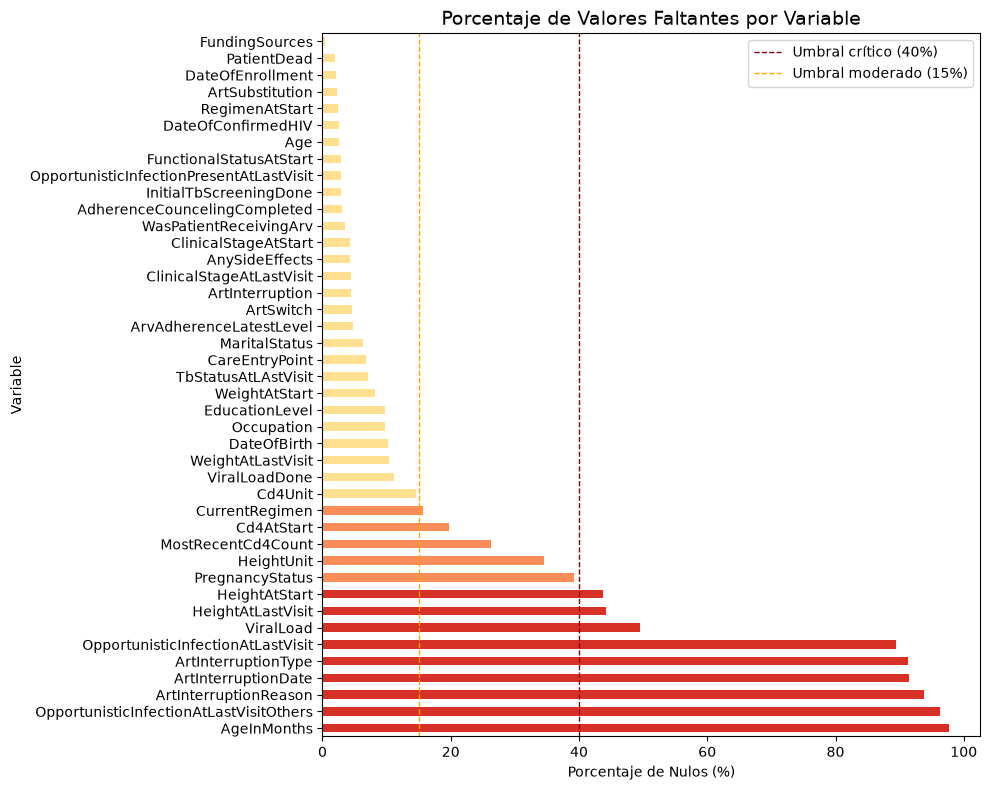

,Conteo,Media,Desv. Estándar,Mínimo,Percentil 25,Mediana,Percentil 75,Máximo,Coef. Variación (%)
Age,26569.00,109.56,12159.49,0.00,27.00,34.00,42.00,1982014.00,11098.57
AgeInMonths,642.00,14.89,80.24,0.00,0.00,2.00,18.00,1987.00,538.82
WeightAtStart,25065.00,54.92,17.12,0.00,47.00,55.00,65.00,100.00,31.18
HeightAtStart,15357.00,142.79,51.77,0.00,150.00,160.00,166.00,980.00,36.26
Cd4AtStart,21906.00,451.51,6625.04,0.00,139.00,267.00,434.00,662645.00,1467.30
WeightAtLastVisit,24444.00,60.01,30.31,0.00,50.00,60.00,69.00,1248.00,50.50
HeightAtLastVisit,15231.00,144.67,335.18,0.00,150.00,160.00,166.00,40914.00,231.69
MostRecentCd4Count,20106.00,654.21,7467.95,0.00,229.00,396.00,600.00,578566.00,1141.52


In [19]:
#Creamos el DataFrame que nos permite visualizar y comprender los elementos de la base de datos:

resumen_variables = pd.DataFrame({

    'Variable': df.columns,                                                   #Asigna cada columna a una fila bajo el nombre de Variable

    'Tipo_Python': df.dtypes.values,                                          #Tipo de dato, detectado por Python

    'Valores_No_Nulos': df.notnull().sum().values,                            #Cantidad de valores no nulos

    'Valores_Nulos': df.isnull().sum().values,                                #Cantidad de valores nulos

    'Pct_Nulos': (df.isnull().mean() * 100).round(2).values,                  #Porcentaje de valores nulos con respecto al total

    'Valores_Unicos': df.nunique().values                                     #Cantidad de valores unicos

})



#Utilizamos pandas para estilizar la tabla creada y crear un gradiente de color rojo que enfatiza
#el porcentaje de valores nulos, y un gradiente verde que enfatiza la presencia de datos no nulos

display(

    resumen_variables.style

    .background_gradient(subset=['Pct_Nulos'], cmap='Reds')

    .background_gradient(subset=['Valores_No_Nulos'], cmap='Greens')

    .format({'Pct_Nulos': '{:.1f}%'})

    .set_caption('Resumen de Variables del Dataset')

)


nulos_pct = (df.isnull().mean() * 100).round(2)

nulos_pct = nulos_pct[nulos_pct > 0].sort_values(ascending=False)



# Graficamos un barplot horizontal para facilitar la lectura de los nombres de variables

fig, ax = plt.subplots(figsize=(10, 8))



colores = ['#d73027' if x > 40 else '#fc8d59' if x > 15 else '#fee090' for x in nulos_pct.values]



nulos_pct.plot(kind='barh', ax=ax, color=colores)



ax.axvline(x=40, color='darkred', linestyle='--', linewidth=1, label='Umbral crítico (40%)')

ax.axvline(x=15, color='orange', linestyle='--', linewidth=1, label='Umbral moderado (15%)')



ax.set_title('Porcentaje de Valores Faltantes por Variable', fontsize=14)

ax.set_xlabel('Porcentaje de Nulos (%)')

ax.set_ylabel('Variable')

ax.legend()

plt.tight_layout()

plt.show()

estadisticas_numericas = (

    df.describe()

    .T #Transponemos las columnas como filas para mayor legibilidad

    .rename(columns={

        'count': 'Conteo',

        'mean': 'Media',

        'std': 'Desv. Estándar',

        'min': 'Mínimo',

        '25%': 'Percentil 25',

        '50%': 'Mediana',

        '75%': 'Percentil 75',

        'max': 'Máximo'

    })

)



# Se calcula el coeficiente de variación indica qué tan dispersos están los datos

# en relación a la media — valores altos sugieren alta variabilidad

estadisticas_numericas['Coef. Variación (%)'] = (

    (estadisticas_numericas['Desv. Estándar'] / estadisticas_numericas['Media']) * 100

).round(2)



display(

    estadisticas_numericas.style

    .background_gradient(cmap='Blues', subset=['Media', 'Desv. Estándar'])

    .background_gradient(cmap='Oranges', subset=['Coef. Variación (%)'])

    .format('{:.2f}')

    .set_caption('Estadísticas Descriptivas — Variables Numéricas')

)